In [19]:
from __future__ import annotations
import operator
import os
from pathlib import Path
from typing import TypedDict, List, Annotated, Literal

from pydantic import BaseModel, Field
from langgraph.graph import StateGraph, START, END
from langgraph.types import Send

from langchain_huggingface import ChatHuggingFace, HuggingFaceEndpoint
from langchain_core.messages import SystemMessage, HumanMessage
from langchain_core.output_parsers import PydanticOutputParser
from langchain_core.prompts import PromptTemplate
from dotenv import load_dotenv

In [20]:
load_dotenv("D:/Agentic AI/Blog-writing-agent/.env", override=True)

True

In [21]:
llm = HuggingFaceEndpoint(
    repo_id="meta-llama/Llama-3.1-8B-Instruct",
    task="text-generation",
    max_new_tokens=2048,
    temperature=0.1,
)

model = ChatHuggingFace(llm=llm)

In [22]:
class Task(BaseModel):
    id: int
    title: str
    goal: str = Field(
        ...,
        description="One sentence describing what the reader should be able to do/understand after this section.",
    )
    bullets: List[str] = Field(
        ...,
        min_length=3,
        max_length=5,
        description="3–5 concrete, non-overlapping subpoints to cover in this section.",
    )
    target_words: int = Field(
        ...,
        description="Target word count for this section (120–450).",
    )
    section_type: Literal[
        "intro", "core", "examples", "checklist", "common_mistakes", "conclusion"
    ] = Field(
        ...,
        description="Use 'common_mistakes' exactly once in the plan.",
    )

In [23]:
class Plan(BaseModel):
    blog_title: str
    audience: str = Field(..., description="Who this blog is for.")
    tone: str = Field(..., description="Writing tone (e.g., practical, crisp).")
    tasks: List[Task]

In [24]:
class State(TypedDict):
    topic: str
    plan: Plan
    sections: Annotated[List[str], operator.add]
    final: str

Orchestrator Node

In [25]:
def orchestrator(state: State) -> dict:
    parser = PydanticOutputParser(pydantic_object=Plan)
    
    prompt = PromptTemplate(
        template=(
            "You are a senior technical writer and developer advocate. Your job is to produce a "
            "highly actionable outline for a technical blog post.\n\n"
            "Hard requirements:\n"
            "- Create 5–7 sections (tasks) that fit a technical blog.\n"
            "- EVERY SINGLE section must include ALL of the following fields:\n"
            "  1) id\n"
            "  2) title\n"
            "  3) goal (1 sentence: what the reader can do/understand after the section)\n"
            "  4) bullets (3–5 concrete, specific, and non-overlapping bullet points)\n"
            "  5) target_words (target word count, e.g., 120–450)\n"
            "  6) section_type (e.g., 'intro', 'core', etc.)\n"
            "- Include EXACTLY ONE section with section_type='common_mistakes'.\n\n"
            "Make it technical (not generic):\n"
            "- Assume the reader is a developer; use correct terminology.\n"
            "- Avoid vague bullets like 'Explain X' or 'Discuss Y'. Every bullet should state what "
            "to build/compare/measure/verify.\n\n"
            "Topic: {topic}\n\n"
            "CRITICAL: You must return valid JSON matching the exact schema below. Do not omit any fields for any task.\n"
            "{format_instructions}\n"
        ),
        input_variables=["topic"],
        partial_variables={"format_instructions": parser.get_format_instructions()},
    )
    
    chain = prompt | model | parser
    plan = chain.invoke({"topic": state['topic']})
    
    return {"plan": plan}

Fanout and Worker Node

In [26]:
def fanout(state: State):
    return [
        Send(
            "worker",
            {"task": task, "topic": state["topic"], "plan": state["plan"]},
        )
        for task in state["plan"].tasks
    ]

In [27]:
def worker(payload: dict) -> dict:
    task = payload["task"]
    topic = payload["topic"]
    plan = payload["plan"]

    bullets_text = "\n- " + "\n- ".join(task.bullets)

    section_md = model.invoke(
        [
            SystemMessage(
                content=(
                    "You are a senior technical writer and developer advocate. Write ONE section of a technical blog post in Markdown.\n\n"
                    "Hard constraints:\n"
                    "- Follow the provided Goal and cover ALL Bullets in order (do not skip or merge bullets).\n"
                    "- Stay close to the Target words (±15%).\n"
                    "- Output ONLY the section content in Markdown (no blog title H1, no extra commentary).\n\n"
                    "Technical quality bar:\n"
                    "- Be precise and implementation-oriented (developers should be able to apply it).\n"
                    "- Prefer concrete details over abstractions: APIs, data structures, protocols, and exact terms.\n"
                    "- When relevant, include at least one of:\n"
                    "  * a small code snippet (minimal, correct, and idiomatic)\n"
                    "  * a tiny example input/output\n"
                    "  * a checklist of steps\n"
                    "  * a diagram described in text (e.g., 'Flow: A -> B -> C')\n"
                    "- Explain trade-offs briefly (performance, cost, complexity, reliability).\n"
                    "- Call out edge cases / failure modes and what to do about them.\n"
                    "- If you mention a best practice, add the 'why' in one sentence.\n\n"
                    "Markdown style:\n"
                    "- Start with a '## <Section Title>' heading.\n"
                    "- Use short paragraphs, bullet lists where helpful, and code fences for code.\n"
                    "- Avoid fluff. Avoid marketing language.\n"
                    "- If you include code, keep it focused on the bullet being addressed.\n"
                )
            ),
            HumanMessage(
                content=(
                    f"Blog: {plan.blog_title}\n"
                    f"Audience: {plan.audience}\n"
                    f"Tone: {plan.tone}\n"
                    f"Topic: {topic}\n\n"
                    f"Section: {task.title}\n"
                    f"Section type: {task.section_type}\n"
                    f"Goal: {task.goal}\n"
                    f"Target words: {task.target_words}\n"
                    f"Bullets:{bullets_text}\n"
                )
            ),
        ]
    ).content.strip()

    return {"sections": [section_md]}

In [28]:
def reducer(state: State) -> dict:
    title = state["plan"].blog_title
    body = "\n\n".join(state["sections"]).strip()
    
    final_md = f"# {title}\n\n{body}\n"

    # Save to file
    filename = "".join(c if c.isalnum() or c in (" ", "_", "-") else "" for c in title)
    filename = filename.strip().lower().replace(" ", "_") + ".md"
    Path(filename).write_text(final_md, encoding="utf-8")

    return {"final": final_md}

In [29]:
# -----------------------------
# Graph Compilation & Execution
# -----------------------------
g = StateGraph(State)
g.add_node("orchestrator", orchestrator)
g.add_node("worker", worker)
g.add_node("reducer", reducer)

g.add_edge(START, "orchestrator")
g.add_conditional_edges("orchestrator", fanout, ["worker"])
g.add_edge("worker", "reducer")
g.add_edge("reducer", END)

app = g.compile()

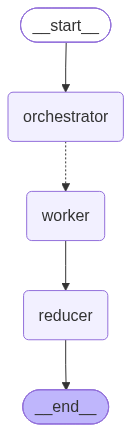

In [30]:
app

In [31]:
out = app.invoke({"topic": "Write a blog on Self Attention", "sections": []})
print(out["final"])

# Self Attention: A Technical Guide

## Introduction to Self Attention

Self attention is a fundamental concept in deep learning that has revolutionized the way we process sequential data. In this section, we'll delve into the concept of self attention, its role in deep learning, and its key differences from other attention mechanisms.

### What is Self Attention?

Self attention, also known as intra-attention, is a mechanism that allows a model to weigh the importance of different elements within a sequence, such as words in a sentence or pixels in an image. This is achieved by computing a weighted sum of the input elements, where the weights are learned during training. The output is a representation of the input sequence that highlights the most important elements.

### Key Differences from Other Attention Mechanisms

There are several attention mechanisms, including:

* **Global Attention**: This mechanism computes a weighted sum of the input elements, but the weights are learned g